# 第5章练习（二）：在单一聚类簇上重做三重障碍与 meta-labeling

[ch5_meta_labeling.ipynb](ch5_meta_labeling.ipynb) 把 488 只基金混在一起训练，得到的方向 AUC 只有 0.521，
meta 分档虽单调但增量有限。一个合理的怀疑是：**混合样本里根本不存在一个统一的「方向生成过程」**。

本 Notebook 验证这个怀疑，并按 [cluster_membership_denoise.csv](cluster_membership_denoise.csv) 的层次聚类结果，
只在**一个簇内部**训练与回测：

1. 先量化各簇的收益过程差异（波动、峰度、簇内相关），说明混合样本为何不可比；
2. 再量化各簇**三重障碍标签分布**的差异——这是「混在一起训练会让模型学成分类器」的直接证据；
3. 在选定簇上完整重跑 (a)–(e)；
4. 用**全样本模型 vs 单簇模型**在同一测试集上的对照，判断按簇训练是否真的更好。

**这不是把 ch5_meta_labeling 的结论推翻**，而是回答一个它回答不了的问题：信号是否只在同质资产内部成立。

## 统一实验约定

数据口径与 [ch5_meta_labeling.ipynb](ch5_meta_labeling.ipynb) 完全一致：读取 `data/hs_funds_prices.parquet`，
最近 1,260 个价格观测，前 1,008 个训练、后 252 个测试，固定种子 42。公共准备见 [notebook_common.py](notebook_common.py)。

标签仍是 Exercise 3 的三重障碍：`PT=20` 个交易日为垂直障碍，止盈止损为 `MULT=0.5 × 20日波动 × √PT`，
决策日次日收盘建仓。

簇标签直接采用 [cluster_membership_denoise.csv](cluster_membership_denoise.csv) 的「层次聚类」列。
该文件的资产顺序已与实验资产池逐一对齐（代码中带断言），因此无需重新聚类，也不引入额外的窗口口径差异。

**唯一的差别**是训练与回测的资产范围：本 Notebook 只用其中一个簇，不再混入其余 11 个簇。

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             roc_auc_score)
from IPython.display import display
from notebook_common import load_data, setup_notebook, timed

SEED = 42
setup_notebook(SEED)
data = load_data()
prices, assets = data.prices, list(data.assets)
display(data.summary())

数据模式                          全部合格基金
每侧缩尾比例                         0.00%
训练期合格基金数                         488
本次使用基金数                          488
训练收益行数                          1007
训练收益区间       2021-07-14 至 2025-09-04
测试候选区间       2025-09-05 至 2026-09-18
测试候选日期数                          252
测试共同有效日期数                        252
排除测试日期数                            0
测试日期覆盖率                      100.00%
Name: 数据概览, dtype: object

## 1. 簇标签与资产异质性

先确认三件事：资产顺序是否严丝合缝、各簇规模是否够训练、各簇的收益过程差多远。

判别「差多远」不能只看波动率——三重障碍的止盈止损本来就按各基金自身波动缩放，已经消掉了一阶差异。
真正不能靠缩放消除的是**高阶矩与相关结构**：偏度决定止盈/止损哪侧更容易先被触发，峰度决定尾部跳变的频率，
簇内相关决定同一天有多少个事件在讲同一个故事。

In [2]:
membership = pd.read_csv('cluster_membership_denoise.csv').set_index('Unnamed: 0')
assert list(membership.index) == assets, '簇成员必须先与实验资产池逐一对齐'
cluster = membership['层次聚类'].astype(int)

X_train = data.X_train
returns_vol = X_train.std() * np.sqrt(252)
returns_mean = X_train.mean() * 252
corr_matrix = X_train.corr()
within = {}
for cid, ids in cluster.groupby(cluster):
    block = corr_matrix.loc[ids.index, ids.index].to_numpy()
    within[cid] = block[np.triu_indices(len(ids), 1)].mean()

profile = pd.DataFrame({
    '规模': cluster.value_counts().sort_index(),
    '占比': cluster.value_counts(normalize=True).sort_index(),
    '年化波动中位': returns_vol.groupby(cluster).median(),
    '年化收益中位': returns_mean.groupby(cluster).median(),
    '偏度中位': X_train.skew().groupby(cluster).median(),
    '峰度中位': X_train.kurt().groupby(cluster).median(),
    '簇内平均相关': pd.Series(within),
})
display(profile.round(4))
print(f'共 {cluster.nunique()} 个簇，规模 {profile["规模"].min()}～{profile["规模"].max()} 只；'
      f'最大簇占全样本 {profile["占比"].max():.1%}')

,规模,占比,年化波动中位,年化收益中位,偏度中位,峰度中位,簇内平均相关
0,14,0.0287,0.2250,0.0948,-0.3434,7.3270,0.6390
1,40,0.0820,0.2561,0.0159,0.1768,3.9658,0.8356
2,64,0.1311,0.1773,-0.0006,0.3948,10.2135,0.8356
3,19,0.0389,0.2663,0.0744,0.9674,7.0327,0.9520
4,59,0.1209,0.1745,0.0760,-0.0610,6.6507,0.6605
5,71,0.1455,0.3008,0.0437,0.3713,3.2898,0.7693
6,34,0.0697,0.2602,-0.1046,0.6694,5.3239,0.8860
7,80,0.1639,0.2845,-0.0310,0.5737,7.3167,0.7870
8,45,0.0922,0.2301,0.0336,0.2195,6.5501,0.7633
9,25,0.0512,0.0117,0.0075,-0.0040,15.5967,0.1851


共 12 个簇，规模 14～80 只；最大簇占全样本 16.4%


### 1.1 簇 9 是货币型基金，而不是「低波动的股票基金」

簇 9 的年化波动中位只有约 1.2%，峰度却高达 15 以上，簇内相关仅 0.19。这是货币/短债类资产的典型特征：
收益近乎常数、偶有微小跳变。

它对三重障碍规则是灾难性的：`MULT × σ × √PT` 在 σ≈0.0007 时给出的止盈止损只有约 0.16%，
于是绝大多数事件在几天内就被微小波动「触发」，退出价几乎不携带方向信息。
把它和波动 30% 的股票型基金放进同一个训练集，模型的节点分裂会优先去区分「这是不是货币基金」，
而不是学习「价格接下来会往哪走」。

### 1.2 同一套三重障碍规则，在各簇上产生的标签分布差异极大

这是本节的核心证据。若各簇的标签分布接近，混合训练没有额外代价；若差异很大，
全样本模型的高准确率就可能来自「先判断这是哪个簇，再套用该簇的先验」。

下面先建全样本事件表（后面所有实验共用），再按簇汇总标签分布。

In [3]:
PT = 20
MULT = 0.5
COST = 0.001
LOOKBACK = 120
TRAIN_PRICES = 1008
TARGET_CLUSTER = 7          # 规模最大的簇（80 只），事件数最多，统计最稳

FEATURES = ['均值收益10日', '均值收益20日', '波动率20日', '偏度60日', '峰度60日',
            '均线差5比20', '均线差10比50', '均线差20比60']
RF_KW = dict(n_estimators=50, max_depth=10, min_samples_leaf=100,
             random_state=SEED, class_weight='balanced_subsample', n_jobs=-1)


def triple_barrier(price, sigma, pt=PT, mult=MULT):
    """按收盘价判定止盈/止损/垂直障碍，返回标签、持有天数与退出价。"""
    values = price.to_numpy()
    n = len(values)
    target = mult * sigma.to_numpy() * np.sqrt(pt)
    padded = np.concatenate([values, np.full(pt + 2, np.nan)])
    windows = np.lib.stride_tricks.sliding_window_view(padded, pt + 2)
    future = windows[1:n + 1, :pt + 1]
    entry = np.full(n, np.nan)
    entry[:-1] = values[1:]
    upper = entry * (1.0 + target)
    lower = entry * (1.0 - target)
    valid = (np.arange(n) + 1 + pt <= n - 1) & np.isfinite(target) & np.isfinite(entry)
    upper_hit = (future >= upper[:, None]) & valid[:, None]
    lower_hit = (future <= lower[:, None]) & valid[:, None]
    first_upper = np.where(upper_hit.any(axis=1), upper_hit.argmax(axis=1), -1)
    first_lower = np.where(lower_hit.any(axis=1), lower_hit.argmax(axis=1), -1)
    take_upper = (first_upper >= 0) & ((first_lower < 0) | (first_upper < first_lower))
    take_lower = (first_lower >= 0) & ((first_upper < 0) | (first_lower < first_upper))
    label = np.where(take_upper, 1.0, np.where(take_lower, -1.0, 0.0))
    hold = np.where(take_upper | take_lower, np.maximum(first_upper, first_lower), pt)
    exit_idx = np.arange(n) + 1 + hold
    exit_price = np.full(n, np.nan)
    ok = (exit_idx < n) & valid
    exit_price[ok] = values[exit_idx[ok]]
    return pd.DataFrame({'标签': label, '持有天数': hold, '退出价': exit_price},
                        index=price.index)


def build_features(price):
    ret = price.pct_change(fill_method=None)
    out = pd.DataFrame(index=price.index)
    out['均值收益10日'] = ret.rolling(10).mean()
    out['均值收益20日'] = ret.rolling(20).mean()
    out['波动率20日'] = ret.rolling(20).std()
    out['偏度60日'] = ret.rolling(60).skew()
    out['峰度60日'] = ret.rolling(60).kurt()
    for short, long in ((5, 20), (10, 50), (20, 60)):
        out[f'均线差{short}比{long}'] = price.rolling(short).mean() / price.rolling(long).mean() - 1.0
    return out


full = pd.read_parquet('data/hs_funds_prices.parquet')
context = full.set_index('timestamp').sort_index().loc[:, assets].iloc[-(len(prices) + LOOKBACK):]
assert context.iloc[-len(prices):].equals(prices), '预热段末尾必须与实验窗口逐值一致'


def build_events(asset_list):
    blocks = []
    for asset in asset_list:
        px = context[asset]
        sigma = px.pct_change(fill_method=None).rolling(20).std()
        block = triple_barrier(px, sigma).join(build_features(px))
        block['建仓价'] = px.shift(-1)
        block['事件日'] = block.index
        block['基金'] = asset
        blocks.append(block.reset_index(drop=True).iloc[LOOKBACK:])
    table = pd.concat(blocks, ignore_index=True)
    table = table.replace([np.inf, -np.inf], np.nan)
    table = table.dropna(subset=['标签', '建仓价', '退出价'] + FEATURES)
    position = {d: i for i, d in enumerate(prices.index)}
    table['窗口位置'] = table['事件日'].map(position)
    table['建仓收益'] = table['退出价'] / table['建仓价'] - 1.0
    return table.sort_values(['窗口位置', '基金']).reset_index(drop=True)


events_all, elapsed = timed('构造全样本三重障碍事件表', lambda: build_events(assets))
events_all['簇'] = events_all['基金'].map(cluster)
print(f'全样本事件表 {events_all.shape}，{events_all["基金"].nunique()} 只基金')

label_mix = events_all.groupby('簇').agg(
    事件数=('标签', 'size'),
    上涨占比=('标签', lambda s: (s == 1).mean()),
    下跌占比=('标签', lambda s: (s == -1).mean()),
    到期占比=('标签', lambda s: (s == 0).mean()),
    平均持有=('持有天数', 'mean'),
)
label_mix['基金数'] = cluster.value_counts()
display(label_mix.round(4))

overall = pd.Series({
    '上涨占比': (events_all['标签'] == 1).mean(),
    '下跌占比': (events_all['标签'] == -1).mean(),
    '到期占比': (events_all['标签'] == 0).mean(),
    '平均持有': events_all['持有天数'].mean(),
}, name='全样本混合')
display(overall.round(4).to_frame().T)

开始：构造全样本三重障碍事件表


完成：构造全样本三重障碍事件表，耗时 3.61 秒


全样本事件表 (601255, 17)，488 只基金


,事件数,上涨占比,下跌占比,到期占比,平均持有,基金数
簇,,,,,,
0,17346,0.4869,0.3993,0.1139,9.5246,14
1,49146,0.4206,0.4828,0.0967,9.4149,40
2,79030,0.4121,0.4910,0.0969,9.4963,64
3,23541,0.3945,0.4798,0.1257,10.1001,19
4,72736,0.4514,0.4309,0.1177,9.7608,59
5,87602,0.4367,0.4776,0.0857,9.0669,71
6,41865,0.3392,0.5539,0.1069,9.5176,34
7,98324,0.3875,0.5161,0.0964,9.2386,80
8,55434,0.4313,0.4758,0.0929,9.3791,45


,上涨占比,下跌占比,到期占比,平均持有
全样本混合,0.4262,0.4625,0.1113,9.5326


**读法**：全样本的「上涨 42.6% / 下跌 46.3%」是 12 个簇的加权平均，对任何一个簇都不成立。
簇 6 上涨 33.9%、下跌 55.4%，簇 10 上涨 54.8%、下跌 27.4%——两个簇的标签先验几乎互为镜像。
簇 9 的到期占比 25.4% 是全样本（11.1%）的两倍多，平均持有天数也最长。

这意味着：**在混合样本上训练时，模型只要识别出「这是哪个簇」，就能显著降低标签的不确定性**，
而这与「预测价格会往哪走」毫无关系。它会把波动率、峰度这类**识别簇的指纹**当成主要分裂依据，
而这些特征在同簇内部对方向的判别力可能很弱。

这正好解释了 [ch5_meta_labeling.ipynb](ch5_meta_labeling.ipynb) 里「波动率 20 日」的不纯度下降高达 0.38 的现象。

## 2. 在选定簇上重建训练/测试集

选定 **簇 7**：规模最大（80 只，占 16.4%），事件数最多，统计最稳。

切分规则与上一本完全一致：训练事件的结束日必须早于测试期首日（purge），测试事件的结束日必须仍在窗口内。

In [4]:
members = cluster[cluster == TARGET_CLUSTER].index
events = events_all[events_all['基金'].isin(members)].reset_index(drop=True)

train_mask = events['窗口位置'] + 1 + events['持有天数'] <= TRAIN_PRICES - 1
test_mask = (events['窗口位置'] >= TRAIN_PRICES) & (events['窗口位置'] + 1 + events['持有天数'] <= len(prices) - 1)
train = events.loc[train_mask].reset_index(drop=True)
test = events.loc[test_mask].reset_index(drop=True)

print(f'簇 {TARGET_CLUSTER}：{len(members)} 只基金')
print(f'训练 {len(train)} 事件 / {train["窗口位置"].nunique()} 个交易日')
print(f'测试 {len(test)} 事件 / {test["窗口位置"].nunique()} 个交易日')
display(pd.DataFrame({
    '训练期': train['标签'].value_counts(normalize=True).sort_index(),
    '测试期': test['标签'].value_counts(normalize=True).sort_index(),
}).round(4))
print(f'全样本训练事件 {int((events_all["窗口位置"] + 1 + events_all["持有天数"] <= TRAIN_PRICES - 1).sum())}，'
      f'单簇仅为其 {len(train) / (events_all["窗口位置"] + 1 + events_all["持有天数"] <= TRAIN_PRICES - 1).sum():.1%}')

簇 7：80 只基金


训练 79319 事件 / 1005 个交易日
测试 18480 事件 / 231 个交易日


,训练期,测试期
标签,,
-1.0,0.5319,0.4528
0.0,0.0997,0.0844
1.0,0.3684,0.4628


全样本训练事件 485536，单簇仅为其 16.3%


## 3. (a) 在簇内训练 primary 随机森林

与上一本相同：三分类标签、8 个特征、`class_weight='balanced_subsample'`。
指标仍以**方向 AUC**（只保留触障事件）为主，三分类准确率仅作参考。

In [5]:
primary = RandomForestClassifier(**RF_KW)
primary.fit(train[FEATURES], train['标签'].astype(int))


def primary_proba(model, frame):
    proba = model.predict_proba(frame[FEATURES])
    columns = list(model.classes_)
    return pd.DataFrame({
        'p_up': proba[:, columns.index(1)],
        'p_down': proba[:, columns.index(-1)],
        'p_flat': proba[:, columns.index(0)],
    }, index=frame.index)


def direction_auc(frame, proba):
    resolved = frame['标签'].to_numpy() != 0
    target = (frame['标签'].to_numpy()[resolved] > 0).astype(int)
    return roc_auc_score(target, proba['p_up'].to_numpy()[resolved]), int(resolved.sum())


train_proba = primary_proba(primary, train)
test_proba = primary_proba(primary, test)

rows = []
for name, frame, proba in (('样本内（训练期）', train, train_proba),
                           ('样本外（测试期）', test, test_proba)):
    call = np.select([proba['p_up'] > proba['p_down'], proba['p_up'] < proba['p_down']],
                     [1, -1], default=0)
    truth = frame['标签'].to_numpy().astype(int)
    auc, resolved = direction_auc(frame, proba)
    rows.append({'三分类准确率': accuracy_score(truth, call),
                 '多数类基线': pd.Series(truth).value_counts(normalize=True).max(),
                 '平衡准确率': balanced_accuracy_score(truth, call),
                 'macro F1': f1_score(truth, call, average='macro'),
                 '方向AUC': auc, '方向样本数': resolved})
display(pd.DataFrame(rows, index=['样本内（训练期）', '样本外（测试期）']).round(4))
display(pd.Series(primary.feature_importances_, index=FEATURES)
        .sort_values(ascending=False).to_frame('不纯度下降').round(4))

,三分类准确率,多数类基线,平衡准确率,macro F1,方向AUC,方向样本数
样本内（训练期）,0.6558,0.5319,0.4701,0.4476,0.7394,71412
样本外（测试期）,0.4970,0.4628,0.3627,0.3423,0.5289,16920


,不纯度下降
波动率20日,0.2530
均线差20比60,0.1555
均线差10比50,0.1266
峰度60日,0.1157
偏度60日,0.0992
均值收益20日,0.0916
均线差5比20,0.0901
均值收益10日,0.0682


## 4. (b) 用同一规则回测

成本按 `2 × COST × |仓位|` 扣除，日频聚合用**当日等权均值**（不是求和）。

In [6]:
def summarize(pnl, position, dates, name, one_way=COST):
    pnl = np.asarray(pnl, dtype=float)
    position = np.asarray(position, dtype=float)
    net = pnl - 2.0 * one_way * np.abs(position)
    daily = pd.Series(net, index=dates).groupby(level=0).mean()
    std = daily.std()
    return pd.Series({
        '下单数': len(net),
        '命中率': float((net > 0).mean()),
        '毛收益/笔': float(pnl.mean()),
        '净收益/笔': float(net.mean()),
        '累计净收益': float(net.sum()),
        '年化净收益': float(daily.mean() * 252),
        '日频Sharpe': float(daily.mean() / std * np.sqrt(252)) if std > 0 else np.nan,
        'Sharpe t值': float(daily.mean() / std * np.sqrt(len(daily))) if std > 0 else np.nan,
    }, name=name)


side = np.where(test_proba['p_up'] > test_proba['p_down'], 1, -1)
test = test.assign(样本外方向=side, 样本外p_up=test_proba['p_up'].to_numpy())
test['primary盈亏'] = test['样本外方向'] * test['建仓收益']
test['primary净盈亏'] = test['primary盈亏'] - 2 * COST * test['样本外方向'].abs()

display(pd.DataFrame([
    summarize(test['primary盈亏'], test['样本外方向'], test['事件日'], '(a) primary 等仓位'),
    summarize(test['建仓收益'], 1.0, test['事件日'], '恒定做多'),
    summarize(-test['建仓收益'], -1.0, test['事件日'], '恒定做空'),
]).round(4))

,下单数,命中率,毛收益/笔,净收益/笔,累计净收益,年化净收益,日频Sharpe,Sharpe t值
(a) primary 等仓位,18480.0,0.5165,0.0028,0.0008,14.1771,0.1933,0.5318,0.5091
恒定做多,18480.0,0.5257,0.0018,-0.0002,-2.8809,-0.0393,-0.0632,-0.0605
恒定做空,18480.0,0.4577,-0.0018,-0.0038,-71.0391,-0.9687,-1.5574,-1.4911


## 5. (c) 走查生成样本外方向并构造 meta 标签

train 期按交易日切 5 折，第 k 折的方向一律由「只用第 k 折之前数据训练的模型」给出，得到训练期的样本外方向。
meta 标签 = 该笔下注是否盈利。

单簇样本量只有全样本的约六分之一，走查后可用样本进一步减少，这是按簇训练必须付出的代价。

In [7]:
N_FOLDS = 5
fold_of_position = {}
for fold, part in enumerate(np.array_split(np.sort(train['窗口位置'].unique()), N_FOLDS)):
    for position in part:
        fold_of_position[position] = fold
train['折'] = train['窗口位置'].map(fold_of_position)


def walk_forward():
    pieces = []
    for fold in range(1, N_FOLDS):
        fit_part = train[train['折'] < fold]
        pred_part = train[train['折'] == fold]
        model = RandomForestClassifier(**RF_KW)
        model.fit(fit_part[FEATURES], fit_part['标签'].astype(int))
        proba = primary_proba(model, pred_part)
        pieces.append(pd.DataFrame({
            'index': pred_part.index,
            '样本外方向': np.where(proba['p_up'] > proba['p_down'], 1, -1),
            '样本外p_up': proba['p_up'].to_numpy(),
        }))
    return pd.concat(pieces)


oos, elapsed = timed(f'{N_FOLDS - 1} 折走查', walk_forward)
train = train.join(oos.set_index('index'))
meta_train = train.dropna(subset=['样本外方向']).copy()
meta_train['主模型盈亏'] = meta_train['样本外方向'] * meta_train['建仓收益']
meta_train['meta标签'] = (meta_train['主模型盈亏'] > 0).astype(int)

print(f'meta 训练样本 {len(meta_train)}（占训练事件 {len(meta_train) / len(train):.1%}）')
print(f'meta 正例比例 {meta_train["meta标签"].mean():.4f}')
display(meta_train.groupby('折').agg(样本数=('meta标签', 'size'),
                                     meta正例比例=('meta标签', 'mean'),
                                     平均毛收益=('主模型盈亏', 'mean')).round(4))

开始：4 折走查


完成：4 折走查，耗时 1.31 秒


meta 训练样本 64035（占训练事件 80.7%）
meta 正例比例 0.4858


,样本数,meta正例比例,平均毛收益
折,,,
1,16080,0.5640,0.0061
2,16080,0.4325,-0.0046
3,16080,0.5547,0.0067
4,15795,0.3903,-0.0055


## 6. (d) 复训 meta 随机森林

主方案仍按练习原文：8 个原始特征 + (a) 的**硬标签方向**。另保留三组对照以分离各部分的贡献。

In [8]:
SCHEMES = {
    '仅方向（纯 meta）': ['样本外方向'],
    '仅 p_up（纯 meta）': ['样本外p_up'],
    '特征 + 方向（练习 a，主方案）': FEATURES + ['样本外方向'],
    '特征 + p_up（对照）': FEATURES + ['样本外p_up'],
}
meta_truth = (test['primary盈亏'] > 0).astype(int).to_numpy()
fitted, rows = {}, []
for name, columns in SCHEMES.items():
    model = RandomForestClassifier(**RF_KW)
    model.fit(meta_train[columns], meta_train['meta标签'])
    probability = model.predict_proba(test[columns])[:, list(model.classes_).index(1)]
    fitted[name] = (model, probability)
    rows.append({'特征数': len(columns), '测试期AUC': roc_auc_score(meta_truth, probability)})
display(pd.DataFrame(rows, index=list(SCHEMES)).round(4))

MAIN = '特征 + 方向（练习 a，主方案）'
display(pd.Series(fitted[MAIN][0].feature_importances_, index=SCHEMES[MAIN])
        .sort_values(ascending=False).to_frame('不纯度下降').round(4))

,特征数,测试期AUC
仅方向（纯 meta）,1,0.4598
仅 p_up（纯 meta）,1,0.5274
特征 + 方向（练习 a，主方案）,9,0.4648
特征 + p_up（对照）,9,0.5124


,不纯度下降
样本外方向,0.1661
峰度60日,0.1264
偏度60日,0.1258
均线差5比20,0.1088
均线差20比60,0.1077
波动率20日,0.1053
均值收益10日,0.0889
均值收益20日,0.0886
均线差10比50,0.0824


## 7. (e) 按 meta 概率调整仓位并重算回测

`仓位 = 主模型方向 × (2 × meta概率 − 1)`。方向由 (a) 决定，规模由 (d) 决定。

,下单数,命中率,毛收益/笔,净收益/笔,累计净收益,年化净收益,日频Sharpe,Sharpe t值
(a) primary 等仓位,18480.0,0.5165,0.0028,0.0008,14.1771,0.1933,0.5318,0.5091
(e) meta 调整仓位,18480.0,0.4759,-0.0003,-0.0009,-17.2357,-0.2350,-1.2989,-1.2436
恒定做多,18480.0,0.5257,0.0018,-0.0002,-2.8809,-0.0393,-0.0632,-0.0605
恒定做空,18480.0,0.4577,-0.0018,-0.0038,-71.0391,-0.9687,-1.5574,-1.4911


meta 概率 vs 主模型每笔毛盈亏：Spearman ρ = -0.0560（p = 2.62e-14）


,平均概率,平均仓位,主模型毛盈亏,meta净收益,样本数
概率档,,,,,
0,0.28006,-0.43987,0.00988,-0.00410,1848
1,0.38693,-0.20751,0.00704,-0.00221,1848
2,0.48004,-0.01262,-0.00138,-0.00002,1848
3,0.54768,-0.02783,0.00334,0.00017,1848
4,0.60242,-0.11812,0.01004,0.00160,1848
5,0.64720,-0.20689,0.00191,-0.00012,1848
6,0.68685,-0.27051,-0.00138,-0.00125,1848
7,0.72339,-0.33036,-0.00247,-0.00200,1848
8,0.76846,-0.37353,-0.00112,-0.00157,1848


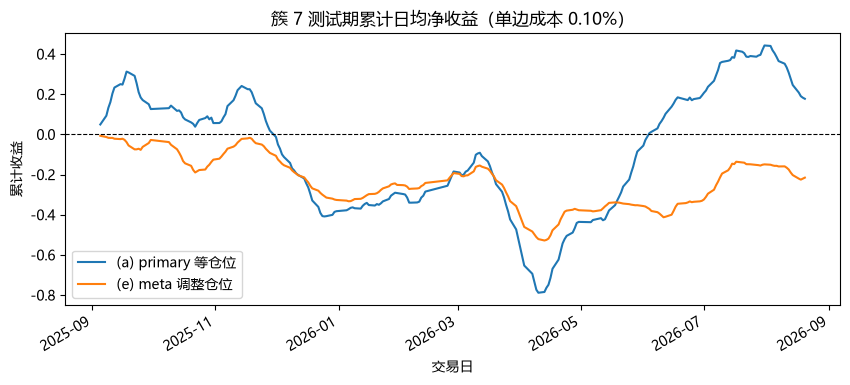

In [9]:
meta_model, meta_probability = fitted[MAIN]
test['meta概率'] = meta_probability
test['仓位'] = test['样本外方向'] * (2.0 * test['meta概率'] - 1.0)
test['meta盈亏'] = test['仓位'] * test['建仓收益']
test['meta净盈亏'] = test['meta盈亏'] - 2 * COST * test['仓位'].abs()

display(pd.DataFrame([
    summarize(test['primary盈亏'], test['样本外方向'], test['事件日'], '(a) primary 等仓位'),
    summarize(test['meta盈亏'], test['仓位'], test['事件日'], '(e) meta 调整仓位'),
    summarize(test['建仓收益'], 1.0, test['事件日'], '恒定做多'),
    summarize(-test['建仓收益'], -1.0, test['事件日'], '恒定做空'),
]).round(4))

test['概率档'] = pd.qcut(test['meta概率'], 10, labels=False, duplicates='drop')
ladder = test.groupby('概率档').agg(平均概率=('meta概率', 'mean'),
                                    平均仓位=('仓位', 'mean'),
                                    主模型毛盈亏=('primary盈亏', 'mean'),
                                    meta净收益=('meta净盈亏', 'mean'),
                                    样本数=('meta盈亏', 'size'))
rho, p_value = stats.spearmanr(test['meta概率'], test['primary盈亏'])
print(f'meta 概率 vs 主模型每笔毛盈亏：Spearman ρ = {rho:.4f}（p = {p_value:.2e}）')
display(ladder.round(5))

fig, ax = plt.subplots()
for name, column in (('(a) primary 等仓位', 'primary净盈亏'), ('(e) meta 调整仓位', 'meta净盈亏')):
    curve = pd.Series(test[column].to_numpy(), index=test['事件日']).groupby(level=0).mean().cumsum()
    curve.plot(ax=ax, label=name)
ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
ax.set(title=f'簇 {TARGET_CLUSTER} 测试期累计日均净收益（单边成本 {COST:.2%}）',
       xlabel='交易日', ylabel='累计收益')
ax.legend()
plt.show()

## 8. 对照：全样本模型 vs 单簇模型

判断「按簇训练是否更好」的唯一干净办法：**在同一批测试事件上比较两个模型**。

- 全样本模型：在 488 只基金的全部训练事件上拟合；
- 单簇模型：只在簇 7 的 80 只基金上拟合；
- 两者都在簇 7 的测试事件上评估。

如果按簇训练真的更好，单簇模型的方向 AUC 与回测指标应更高；如果更差，说明样本量损失压倒了同质性收益。

In [10]:
all_train_mask = events_all['窗口位置'] + 1 + events_all['持有天数'] <= TRAIN_PRICES - 1
all_train = events_all.loc[all_train_mask].reset_index(drop=True)
print(f'全样本训练事件 {len(all_train)}，为单簇的 {len(all_train) / len(train):.1f} 倍')

pooled = RandomForestClassifier(**RF_KW)
pooled.fit(all_train[FEATURES], all_train['标签'].astype(int))
pooled_proba = primary_proba(pooled, test)
pooled_side = np.where(pooled_proba['p_up'] > pooled_proba['p_down'], 1, -1)
pooled_pnl = pooled_side * test['建仓收益']

rows = []
for name, model, proba in (('全样本模型（488 只训练）', pooled, pooled_proba),
                           (f'单簇模型（簇 {TARGET_CLUSTER}，{len(members)} 只训练）', primary, test_proba)):
    auc, resolved = direction_auc(test, proba)
    call = np.select([proba['p_up'] > proba['p_down'], proba['p_up'] < proba['p_down']],
                     [1, -1], default=0)
    rows.append({'方向AUC（簇内测试集）': auc,
                 '三分类准确率': accuracy_score(test['标签'].to_numpy().astype(int), call),
                 '平衡准确率': balanced_accuracy_score(test['标签'].to_numpy().astype(int), call)})
display(pd.DataFrame(rows, index=['全样本模型（488 只训练）',
                                  f'单簇模型（簇 {TARGET_CLUSTER}，{len(members)} 只训练）']).round(4))

importance = pd.DataFrame({
    '全样本模型': pooled.feature_importances_,
    f'簇 {TARGET_CLUSTER} 模型': primary.feature_importances_,
}, index=FEATURES).sort_values('全样本模型', ascending=False)
display(importance.round(4))

display(pd.DataFrame([
    summarize(test['primary盈亏'], test['样本外方向'], test['事件日'], f'单簇模型（簇 {TARGET_CLUSTER}）'),
    summarize(pooled_pnl, pooled_side, test['事件日'], '全样本模型'),
]).round(4))

全样本训练事件 485536，为单簇的 6.1 倍


,方向AUC（簇内测试集）,三分类准确率,平衡准确率
全样本模型（488 只训练）,0.5139,0.492,0.3601
单簇模型（簇 7，80 只训练）,0.5289,0.497,0.3627


,全样本模型,簇 7 模型
波动率20日,0.3835,0.2530
峰度60日,0.1608,0.1157
偏度60日,0.0899,0.0992
均线差20比60,0.0890,0.1555
均线差10比50,0.0847,0.1266
均值收益20日,0.0785,0.0916
均线差5比20,0.0659,0.0901
均值收益10日,0.0476,0.0682


,下单数,命中率,毛收益/笔,净收益/笔,累计净收益,年化净收益,日频Sharpe,Sharpe t值
单簇模型（簇 7）,18480.0,0.5165,0.0028,0.0008,14.1771,0.1933,0.5318,0.5091
全样本模型,18480.0,0.5028,0.0028,0.0008,14.5393,0.1983,0.4003,0.3833


## 结论与限制

**1. 混合样本确实存在结构性代价，且被数据证实**

按同一套三重障碍规则，各簇标签分布从「上涨 33.9% / 下跌 55.4%」（簇 6）到「上涨 54.8% / 下跌 27.4%」（簇 10）。
簇 9（货币型，年化波动 1.2%、峰度 15.6）的到期占比 25.4%、平均持有 10.9 天，均为全样本的两倍。
全样本的 42.6/46.3 只是加权平均，对任何一个簇都不成立。这给了混合模型一条捷径：
**先识别簇，再套先验**，而不是预测方向。

**2. 特征重要性的迁移直接印证了「模型在用波动率识别资产类别」**

| 特征 | 全样本模型 | 簇 7 模型 | 变化 |
| --- | --- | --- | --- |
| 波动率 20 日 | 0.3835 | 0.2530 | −34% |
| 峰度 60 日 | 0.1608 | 0.1157 | −28% |
| 均线差 20 比 60 | 0.0890 | 0.1555 | +75% |
| 均线差 10 比 50 | 0.0847 | 0.1266 | +49% |

去掉跨簇异质性后，「识别这是哪类资产」的指纹特征让位给时序形态特征。这与第 1 节的推断一致。

**3. 按簇训练对 (a) 有微弱改善，但对 meta-labeling 是净损害**

| 模型 | 方向 AUC | 三分类准确率 | 回测 Sharpe |
| --- | --- | --- | --- |
| 全样本（488 只训练） | 0.5139 | 0.4920 | 0.400 |
| 单簇（簇 7，80 只训练） | **0.5289** | **0.4970** | **0.532** |

方向判别确实变好了（AUC +0.015），但幅度远小于样本量的损失（训练事件从 48.5 万降到 7.9 万，仅 16.3%）。

而 (d)(e) 在单簇上**完全失效**：

- 主方案（特征 + 硬标签方向）测试期 AUC **0.4648**，低于 0.5；
- 仅方向（纯 meta）AUC 0.4598，同样低于 0.5；
- 仓位调整后每笔净收益 **−0.0009**、日频 Sharpe **−1.30**，比等仓位 primary（0.0008 / 0.53）更差；
- meta 概率与主模型每笔盈亏的 Spearman ρ = **−0.056**（负相关），分档表的「主模型毛盈亏」列毫无规律。

**4. 为什么 meta-labeling 在单簇上失效**

三个可查的原因：

- **样本量不足**：meta 训练样本从 38.9 万降到 6.4 万，随机森林在 `min_samples_leaf=100` 下已经很勉强。
- **走查各折极不稳定**：四折的 meta 正例比例依次为 0.564 / 0.433 / 0.555 / 0.390，跳幅达 17 个百分点，
  说明单簇方向预测的可靠性随时间剧烈变化；meta 模型学到的更像是「哪段时间好用」而不是「哪笔下注好」。
- **簇内相关更高**：簇 7 的平均相关约 0.79（混合后更低），走查时同一折内的基金事件高度同步，
  有效独立样本进一步缩水，meta 标签的噪声被放大。

**5. 实践结论**

「按簇训练」这个方向是对的，但**只做一半会适得其反**：

- 分层聚类给出的同质性只对 **primary 方向任务**有帮助，对二级 meta 任务反而有害；
- 单簇 80 只、7.9 万训练事件不足以支撑两层模型；
- 若要真正利用聚类，正确做法是**按簇分别训练、按簇分别回测，再在组合层面聚合**，
  而不是把资产池缩到一簇。跳过分层直接缩池，等于用样本量换同质性，且换得不划算。

**限制**

- 簇划分来自 [cluster_membership_denoise.csv](cluster_membership_denoise.csv)，轮廓系数约 0.21 属弱分离，簇边界不稳固。
- 只做了簇 7 一个簇，而它是规模最大（80 只）的簇，对「按簇训练」已是最有利的情形；
  其余簇样本更少，结果只会更差。因此本节结论不依赖「选错了簇」这一解释。
- 测试期 231 个交易日，簇内相关约 0.79，有效独立样本远少于 18480。
- 仍为双侧三重障碍，公募基金无法做空；未计冲击成本与容量约束。